In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pandas_datareader import data as web
from statsmodels.tsa.stattools import adfuller

import warnings
warnings.filterwarnings("ignore")

plt.style.use("seaborn-v0_8-whitegrid")

In [3]:
START_DATE = "2006-01-01"
END_DATE = "2026-08-31"

start = pd.Timestamp(START_DATE)
end = pd.Timestamp(END_DATE)

In [4]:
series = {
    # House prices
    "Case_Shiller_HPI": "CSUSHPINSA",
    "FHFA_HPI": "USSTHPI",

    # Prices
    "Median_New_Home_Price": "MSPUS",
    "Average_New_Home_Price": "ASPNHSUS",

    # Sales
    "Existing_Home_Sales": "EXHOSLUSM495S",
    "New_Home_Sales": "HSN1F",

    # Construction
    "Housing_Starts": "HOUST",
    "Building_Permits": "PERMIT",

    # Inventory / supply
    "Months_Supply_New_Homes": "MSACSR",

    # Homeownership
    "Homeownership_Rate": "RHORUSQ156N",

    # Mortgage / interest rates
    "Mortgage_Rate_30Y": "MORTGAGE30US",
    "Fed_Funds_Rate": "FEDFUNDS",

    # Inflation / economy
    "CPI": "CPIAUCSL",
    "Unemployment": "UNRATE",
    "Real_GDP": "GDPC1",

    # Financial conditions
    "Mortgage_Debt": "HHMSDODNS",
}

data = pd.DataFrame()

for name, ticker in series.items():
    try:
        temp = web.DataReader(
            ticker,
            "fred",
            start,
            end
        )
        temp.columns = [name]
        
        if data.empty:
            data = temp
        else:
            data = data.join(temp, how="outer")
            
        print(f"Downloaded: {name}")
        
    except Exception as e:
        print(f"FAILED: {name} -> {e}")

data.head()

Downloaded: Case_Shiller_HPI
Downloaded: FHFA_HPI
Downloaded: Median_New_Home_Price
Downloaded: Average_New_Home_Price
Downloaded: Existing_Home_Sales
Downloaded: New_Home_Sales
Downloaded: Housing_Starts
Downloaded: Building_Permits
Downloaded: Months_Supply_New_Homes
Downloaded: Homeownership_Rate
Downloaded: Mortgage_Rate_30Y
Downloaded: Fed_Funds_Rate
Downloaded: CPI
Downloaded: Unemployment
Downloaded: Real_GDP
Downloaded: Mortgage_Debt


,Case_Shiller_HPI,FHFA_HPI,Median_New_Home_Price,Average_New_Home_Price,Existing_Home_Sales,New_Home_Sales,Housing_Starts,Building_Permits,Months_Supply_New_Homes,Homeownership_Rate,Mortgage_Rate_30Y,Fed_Funds_Rate,CPI,Unemployment,Real_GDP,Mortgage_Debt
DATE,,,,,,,,,,,,,,,,
2006-01-01,180.828,368.22,247700.0,301000.0,NaN,1174.0,2273.0,2212.0,5.3,68.5,NaN,4.29,199.3,4.7,16353.835,9195175.0
2006-01-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.21,NaN,NaN,NaN,NaN,NaN
2006-01-12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.15,NaN,NaN,NaN,NaN,NaN
2006-01-19,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.10,NaN,NaN,NaN,NaN,NaN
2006-01-26,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.12,NaN,NaN,NaN,NaN,NaN


In [5]:
print("Shape:", data.shape)

print("\nDate range:")
print(data.index.min(), "to", data.index.max())

print("\nMissing values:")
print(data.isna().sum())

print("\nData frequency:")
print(data.index.to_series().diff().value_counts().head(10))

Shape: (1295, 16)

Date range:
2006-01-01 00:00:00 to 2026-08-27 00:00:00

Missing values:
Case_Shiller_HPI           1049
FHFA_HPI                   1213
Median_New_Home_Price      1213
Average_New_Home_Price     1047
Existing_Home_Sales        1282
New_Home_Sales             1047
Housing_Starts             1047
Building_Permits           1047
Months_Supply_New_Homes    1047
Homeownership_Rate         1213
Mortgage_Rate_30Y           217
Fed_Funds_Rate             1047
CPI                        1048
Unemployment               1048
Real_GDP                   1213
Mortgage_Debt              1213
dtype: int64

Data frequency:
DATE
7 days    827
6 days     99
1 days     76
4 days     72
2 days     72
5 days     69
3 days     65
8 days     14
Name: count, dtype: int64


CLEANING

In [6]:
monthly = data.resample("ME").mean()

monthly = monthly.loc[
    (monthly.index >= START_DATE) &
    (monthly.index <= END_DATE)
]

monthly.head()

,Case_Shiller_HPI,FHFA_HPI,Median_New_Home_Price,Average_New_Home_Price,Existing_Home_Sales,New_Home_Sales,Housing_Starts,Building_Permits,Months_Supply_New_Homes,Homeownership_Rate,Mortgage_Rate_30Y,Fed_Funds_Rate,CPI,Unemployment,Real_GDP,Mortgage_Debt
DATE,,,,,,,,,,,,,,,,
2006-01-31,180.828,368.22,247700.0,301000.0,NaN,1174.0,2273.0,2212.0,5.3,68.5,6.1450,4.29,199.3,4.7,16353.835,9195175.0
2006-02-28,181.499,NaN,NaN,307900.0,NaN,1061.0,2119.0,2141.0,6.1,NaN,6.2525,4.49,199.4,4.8,NaN,NaN
2006-03-31,182.749,NaN,NaN,298800.0,NaN,1116.0,1969.0,2118.0,5.9,NaN,6.3240,4.59,199.7,4.7,NaN,NaN
2006-04-30,183.648,372.01,246300.0,310300.0,NaN,1123.0,1821.0,1998.0,6.3,68.7,6.5075,4.79,200.7,4.7,16396.151,9505630.0
2006-05-31,184.380,NaN,NaN,293900.0,NaN,1086.0,1942.0,1905.0,6.2,NaN,6.5975,4.94,201.3,4.6,NaN,NaN


In [7]:
monthly = monthly.interpolate(method="linear", limit_direction="both")

In [8]:
monthly["HPI_Return"] = (
    monthly["Case_Shiller_HPI"]
    .pct_change() * 100
)
monthly["HPI_YoY"] = (
    monthly["Case_Shiller_HPI"]
    .pct_change(12) * 100
)
monthly["Mortgage_Rate_Change"] = (
    monthly["Mortgage_Rate_30Y"].diff()
)
monthly["CPI_YoY"] = (
    monthly["CPI"]
    .pct_change(12) * 100
)
monthly["Real_Mortgage_Rate"] = (
    monthly["Mortgage_Rate_30Y"]
    - monthly["CPI_YoY"]
)
monthly["Housing_Starts_YoY"] = (
    monthly["Housing_Starts"]
    .pct_change(12) * 100
)
monthly["Existing_Sales_YoY"] = (
    monthly["Existing_Home_Sales"]
    .pct_change(12) * 100
)

In [9]:
monthly["Case_Shiller_Normalized"] = (
    monthly["Case_Shiller_HPI"]
    / monthly["Case_Shiller_HPI"].iloc[0]
    * 100
)

monthly["FHFA_Normalized"] = (
    monthly["FHFA_HPI"]
    / monthly["FHFA_HPI"].iloc[0]
    * 100
)

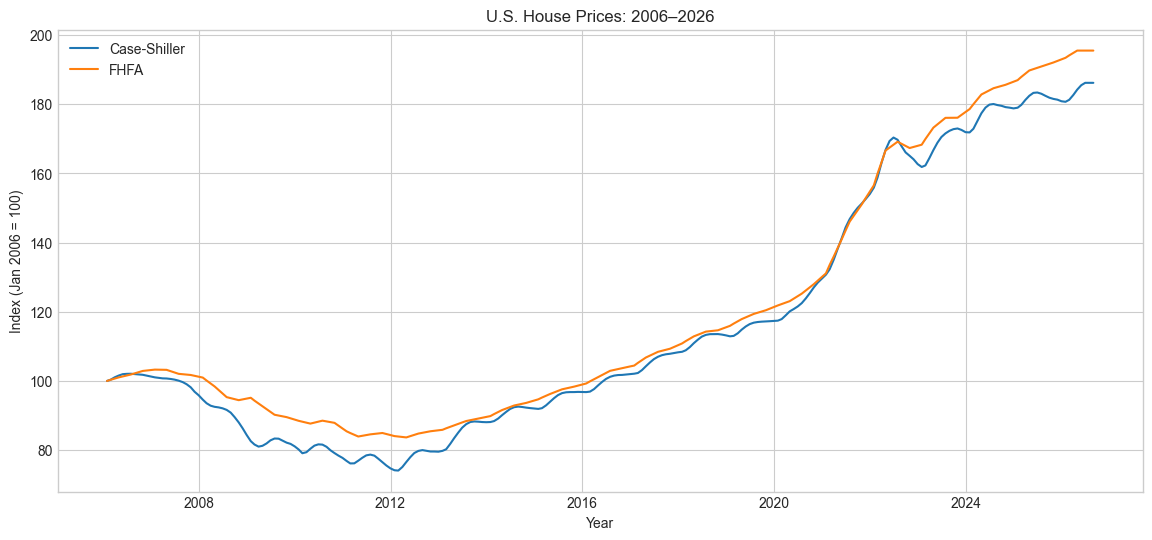

In [10]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly.index,
    monthly["Case_Shiller_Normalized"],
    label="Case-Shiller"
)

plt.plot(
    monthly.index,
    monthly["FHFA_Normalized"],
    label="FHFA"
)

plt.title("U.S. House Prices: 2006–2026")
plt.xlabel("Year")
plt.ylabel("Index (Jan 2006 = 100)")
plt.legend()

plt.show()

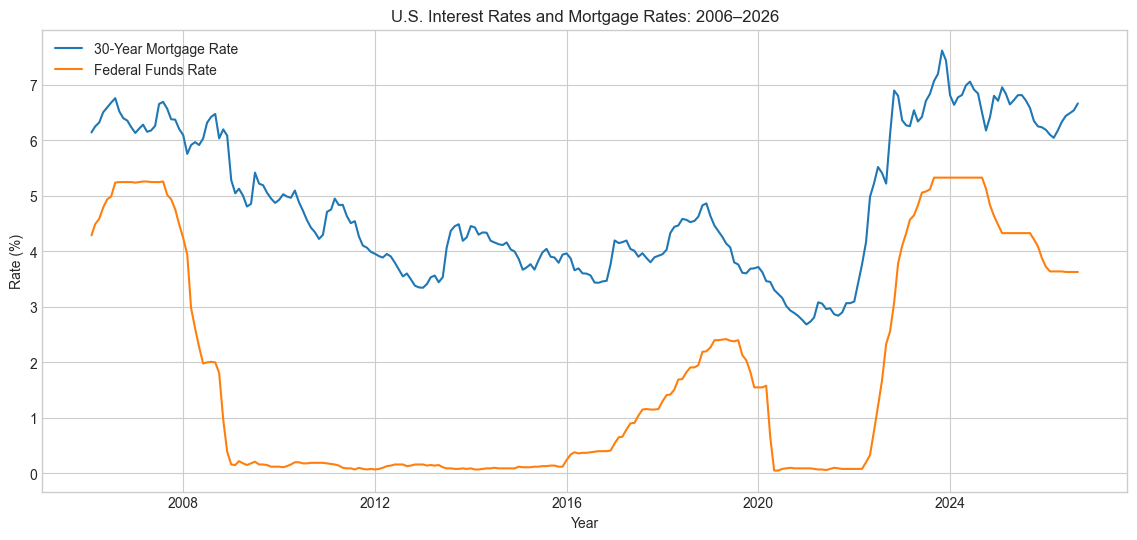

In [11]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly.index,
    monthly["Mortgage_Rate_30Y"],
    label="30-Year Mortgage Rate"
)

plt.plot(
    monthly.index,
    monthly["Fed_Funds_Rate"],
    label="Federal Funds Rate"
)

plt.title("U.S. Interest Rates and Mortgage Rates: 2006–2026")
plt.xlabel("Year")
plt.ylabel("Rate (%)")
plt.legend()

plt.show()

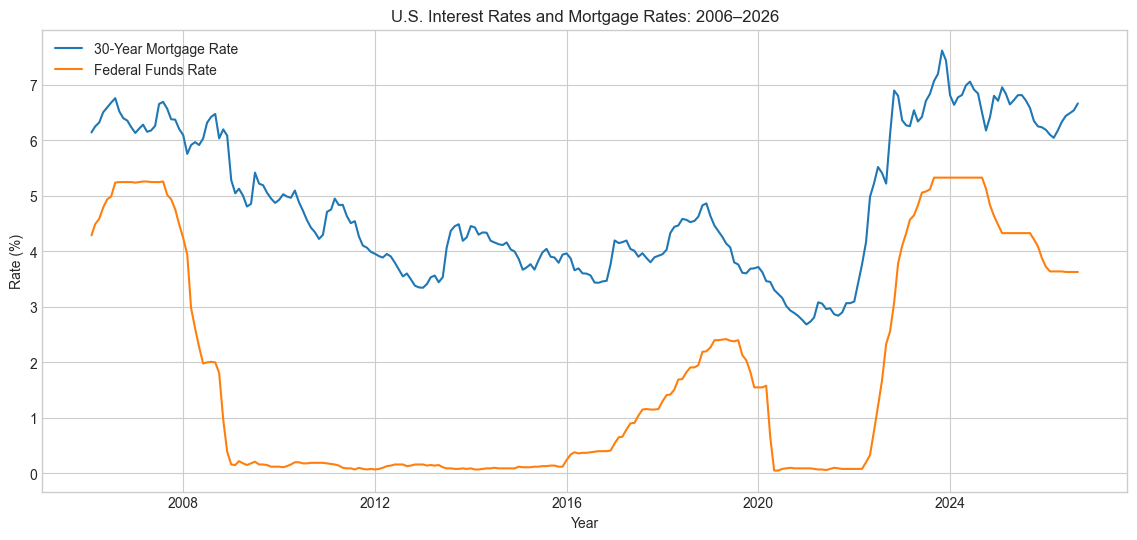

In [12]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly.index,
    monthly["Mortgage_Rate_30Y"],
    label="30-Year Mortgage Rate"
)

plt.plot(
    monthly.index,
    monthly["Fed_Funds_Rate"],
    label="Federal Funds Rate"
)

plt.title("U.S. Interest Rates and Mortgage Rates: 2006–2026")
plt.xlabel("Year")
plt.ylabel("Rate (%)")
plt.legend()

plt.show()

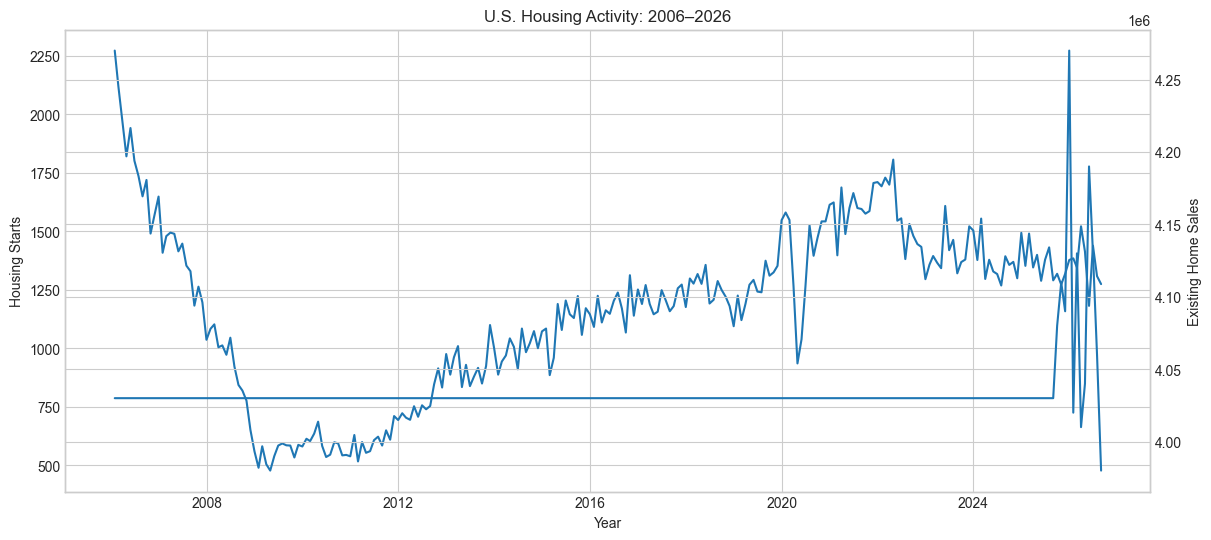

In [13]:
fig, ax1 = plt.subplots(figsize=(14, 6))

ax1.plot(
    monthly.index,
    monthly["Housing_Starts"],
    label="Housing Starts"
)

ax1.set_xlabel("Year")
ax1.set_ylabel("Housing Starts")

ax2 = ax1.twinx()

ax2.plot(
    monthly.index,
    monthly["Existing_Home_Sales"],
    label="Existing Home Sales"
)

ax2.set_ylabel("Existing Home Sales")

plt.title("U.S. Housing Activity: 2006–2026")

plt.show()

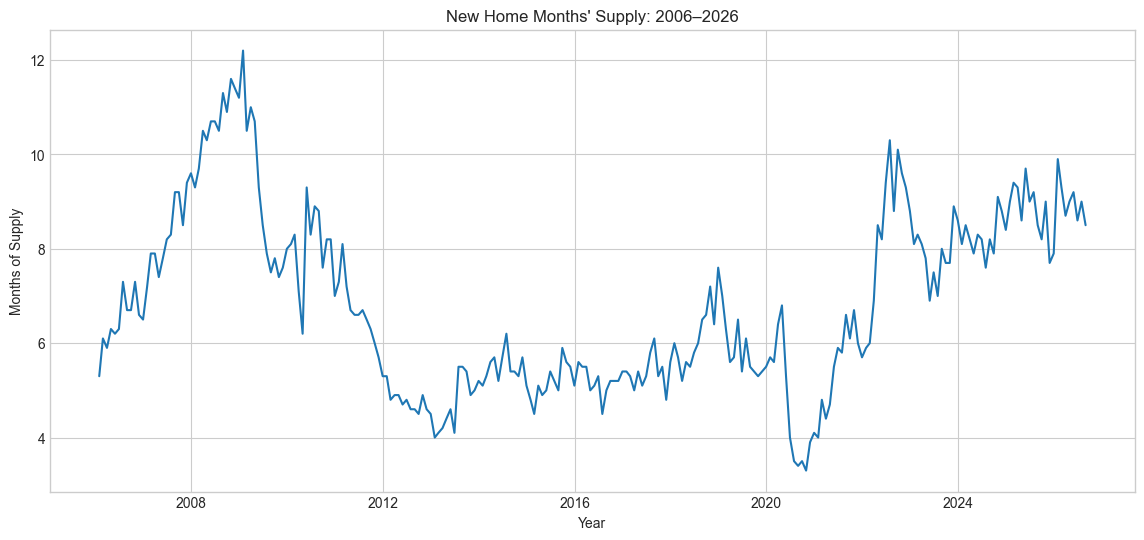

In [14]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly.index,
    monthly["Months_Supply_New_Homes"]
)

plt.title("New Home Months' Supply: 2006–2026")
plt.xlabel("Year")
plt.ylabel("Months of Supply")

plt.show()

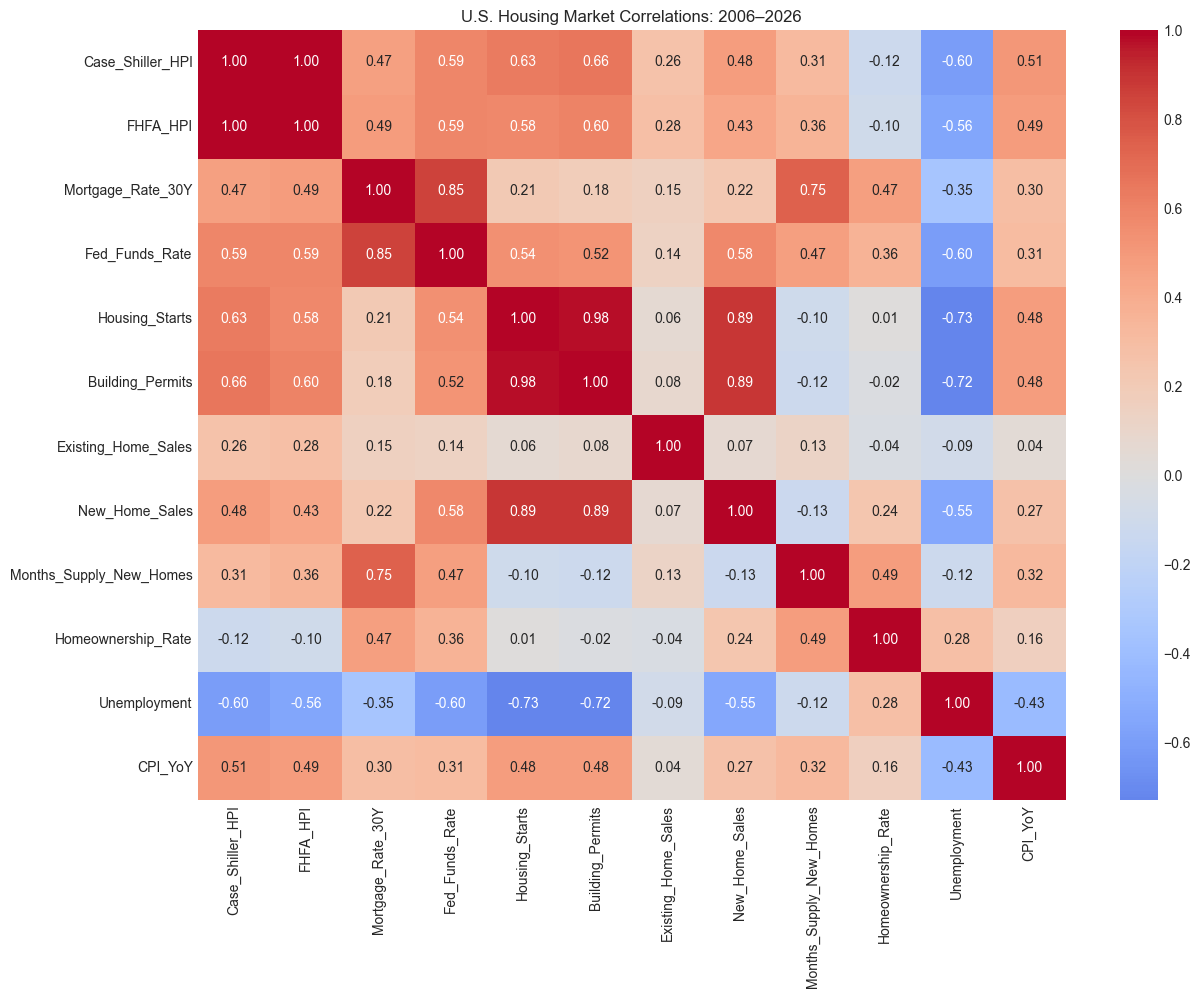

In [15]:
analysis_columns = [
    "Case_Shiller_HPI",
    "FHFA_HPI",
    "Mortgage_Rate_30Y",
    "Fed_Funds_Rate",
    "Housing_Starts",
    "Building_Permits",
    "Existing_Home_Sales",
    "New_Home_Sales",
    "Months_Supply_New_Homes",
    "Homeownership_Rate",
    "Unemployment",
    "CPI_YoY"
]

corr = monthly[analysis_columns].corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("U.S. Housing Market Correlations: 2006–2026")

plt.show()

In [16]:
monthly["HPI_Peak"] = (
    monthly["Case_Shiller_HPI"]
    .cummax()
)

monthly["HPI_Drawdown"] = (
    monthly["Case_Shiller_HPI"]
    / monthly["HPI_Peak"]
    - 1
) * 100

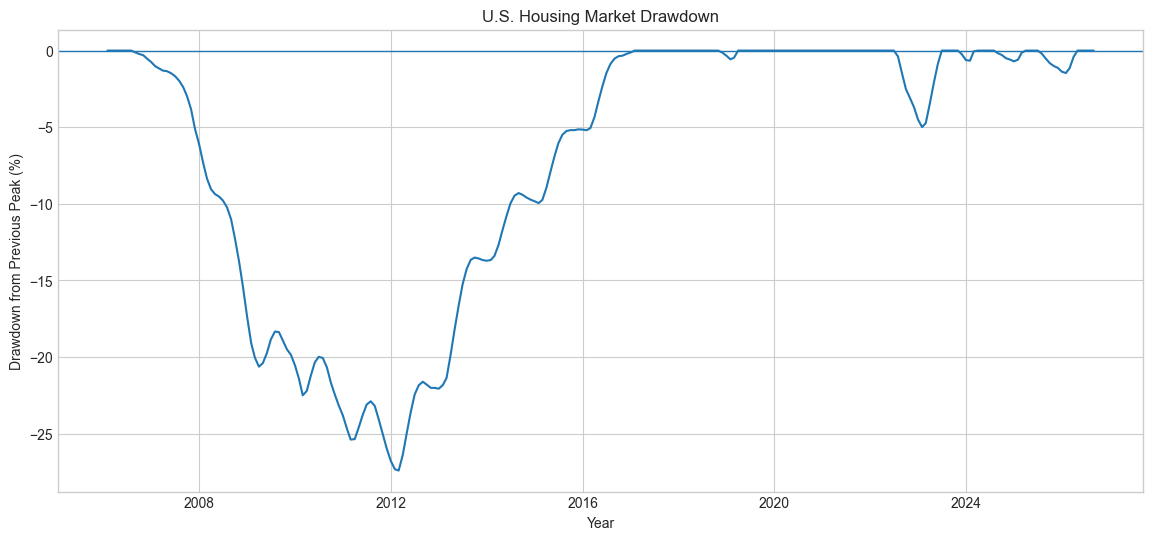

In [17]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly.index,
    monthly["HPI_Drawdown"]
)

plt.axhline(
    0,
    linewidth=1
)

plt.title("U.S. Housing Market Drawdown")
plt.xlabel("Year")
plt.ylabel("Drawdown from Previous Peak (%)")

plt.show()

In [18]:
worst_months = (
    monthly[
        ["Case_Shiller_HPI", "HPI_Return", "HPI_Drawdown"]
    ]
    .sort_values("HPI_Return")
    .head(20)
)

worst_months

,Case_Shiller_HPI,HPI_Return,HPI_Drawdown
DATE,,,
2008-12-31,152.543,-2.260510,-17.368789
2009-01-31,149.360,-2.086625,-19.092992
2008-11-30,156.071,-1.941430,-15.457702
2008-10-31,159.161,-1.697857,-13.783876
2008-09-30,161.910,-1.439659,-12.294767
2010-02-28,143.055,-1.343420,-22.508356
2007-11-30,175.161,-1.333867,-5.116816
2008-01-31,171.076,-1.303826,-7.329625
2011-11-30,136.652,-1.261579,-25.976805


In [19]:
annual = monthly.resample("YE").agg({
    "Case_Shiller_HPI": "mean",
    "FHFA_HPI": "mean",
    "Median_New_Home_Price": "mean",
    "Existing_Home_Sales": "mean",
    "New_Home_Sales": "mean",
    "Housing_Starts": "mean",
    "Building_Permits": "mean",
    "Months_Supply_New_Homes": "mean",
    "Mortgage_Rate_30Y": "mean",
    "Fed_Funds_Rate": "mean",
    "Unemployment": "mean",
    "CPI_YoY": "mean"
})

annual.index = annual.index.year

annual.head()

,Case_Shiller_HPI,FHFA_HPI,Median_New_Home_Price,Existing_Home_Sales,New_Home_Sales,Housing_Starts,Building_Permits,Months_Supply_New_Homes,Mortgage_Rate_30Y,Fed_Funds_Rate,Unemployment,CPI_YoY
DATE,,,,,,,,,,,,
2006,183.480833,374.557500,244558.333333,4030000.0,1049.333333,1811.916667,1843.666667,6.433333,6.410833,4.964167,4.608333,NaN
2007,179.941250,376.990833,242991.666667,4030000.0,768.666667,1341.833333,1391.500000,8.383333,6.340458,5.019167,4.616667,2.869312
2008,164.057917,356.474167,227425.000000,4030000.0,482.166667,900.000000,895.833333,10.675000,6.036125,1.927500,5.800000,3.825691
2009,148.551333,336.332500,216858.333333,4030000.0,374.250000,554.000000,582.000000,9.033333,5.041375,0.160000,9.283333,-0.307388
2010,144.661000,323.630833,223033.333333,4030000.0,321.250000,585.500000,603.666667,8.000000,4.690583,0.175000,9.608333,1.640733


In [20]:
annual["House_Price_Return"] = (
    annual["Case_Shiller_HPI"]
    .pct_change() * 100
)

annual["House_Price_Return"]

DATE
2006          NaN
2007    -1.929130
2008    -8.826955
2009    -9.451896
2010    -2.618848
2011    -3.751702
2012     1.252271
2013     9.600243
2014     6.571841
2015     4.542788
2016     5.079017
2017     5.785346
2018     5.785856
2019     3.444714
2020     6.046270
2021    17.067428
2022    14.754523
2023     2.486432
2024     5.108923
2025     2.231893
2026     1.337075
Name: House_Price_Return, dtype: float64

In [21]:
with pd.ExcelWriter(
    "US_Real_Estate_Market_2006_2026.xlsx",
    engine="openpyxl"
) as writer:
    
    data.to_excel(
        writer,
        sheet_name="Raw_Data"
    )
    
    monthly.to_excel(
        writer,
        sheet_name="Monthly_Data"
    )
    
    annual.to_excel(
        writer,
        sheet_name="Annual_Data"
    )
    
    corr.to_excel(
        writer,
        sheet_name="Correlation"
    )

print("Saved: US_Real_Estate_Market_2006_2026.xlsx")

Saved: US_Real_Estate_Market_2006_2026.xlsx


In [22]:
monthly["HPI_Log_Return"] = np.log(
    monthly["Case_Shiller_HPI"] /
    monthly["Case_Shiller_HPI"].shift(1)
)

In [23]:
monthly["Case_Shiller_Log_Return"] = (
    np.log(monthly["Case_Shiller_HPI"]).diff()
)

monthly["FHFA_Log_Return"] = (
    np.log(monthly["FHFA_HPI"]).diff()
)

In [24]:
monthly["Case_Shiller_Log_Return_Pct"] = (
    monthly["Case_Shiller_Log_Return"] * 100
)

monthly["FHFA_Log_Return_Pct"] = (
    monthly["FHFA_Log_Return"] * 100
)

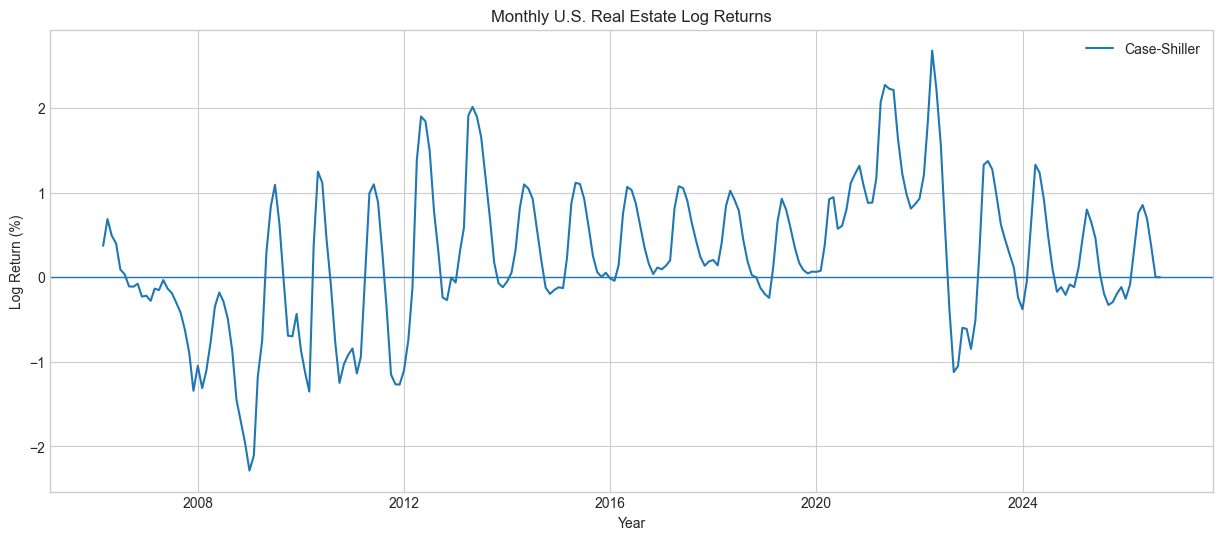

In [25]:
plt.figure(figsize=(15, 6))

plt.plot(
    monthly.index,
    monthly["Case_Shiller_Log_Return_Pct"],
    label="Case-Shiller"
)

plt.axhline(0, linewidth=1)

plt.title("Monthly U.S. Real Estate Log Returns")
plt.xlabel("Year")
plt.ylabel("Log Return (%)")
plt.legend()

plt.show()

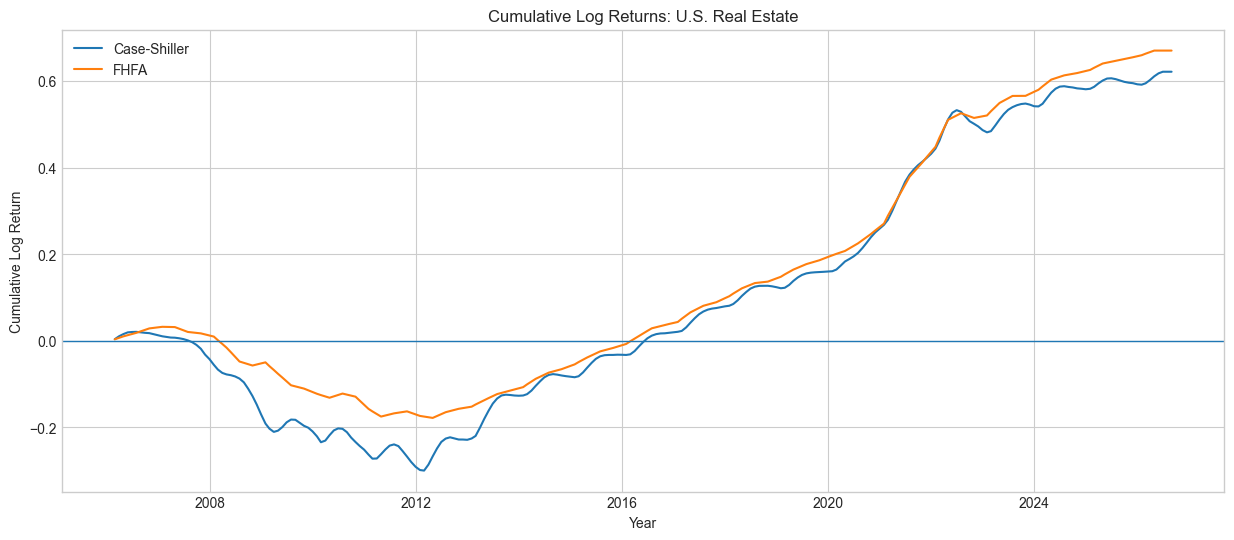

In [26]:
monthly["Case_Shiller_Cumulative_Return"] = (
    monthly["Case_Shiller_Log_Return"]
    .cumsum()
)

monthly["FHFA_Cumulative_Return"] = (
    monthly["FHFA_Log_Return"]
    .cumsum()
)
plt.figure(figsize=(15, 6))

plt.plot(
    monthly.index,
    monthly["Case_Shiller_Cumulative_Return"],
    label="Case-Shiller"
)

plt.plot(
    monthly.index,
    monthly["FHFA_Cumulative_Return"],
    label="FHFA"
)

plt.axhline(0, linewidth=1)

plt.title("Cumulative Log Returns: U.S. Real Estate")
plt.xlabel("Year")
plt.ylabel("Cumulative Log Return")
plt.legend()

plt.show()

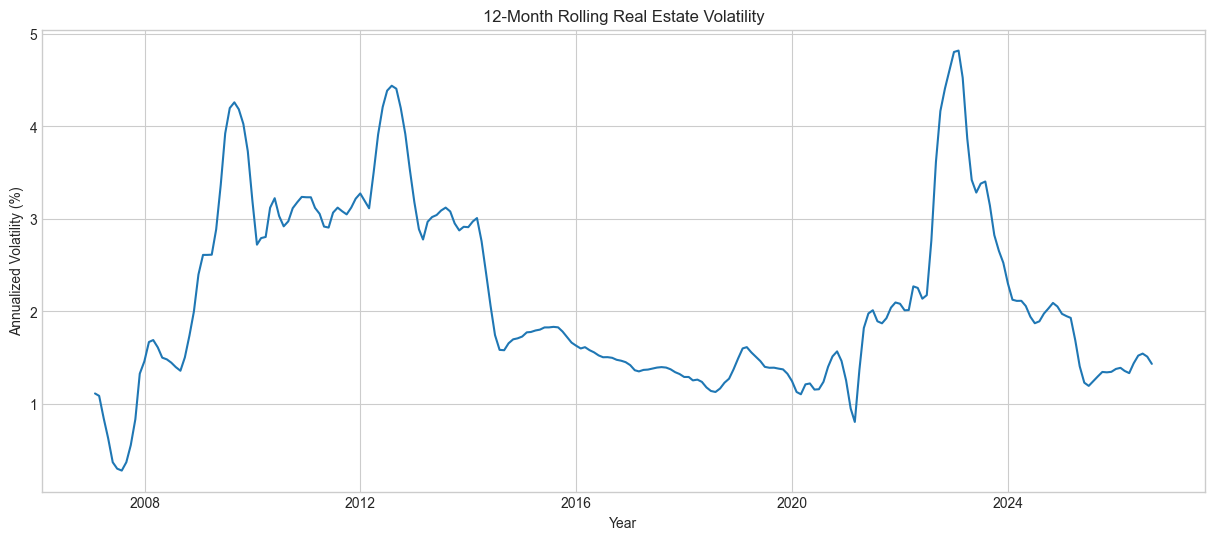

In [27]:
monthly["Case_Shiller_Rolling_Volatility"] = (
    monthly["Case_Shiller_Log_Return"]
    .rolling(12)
    .std()
    * np.sqrt(12)
    * 100
)
plt.figure(figsize=(15, 6))

plt.plot(
    monthly.index,
    monthly["Case_Shiller_Rolling_Volatility"]
)

plt.title("12-Month Rolling Real Estate Volatility")
plt.xlabel("Year")
plt.ylabel("Annualized Volatility (%)")

plt.show()

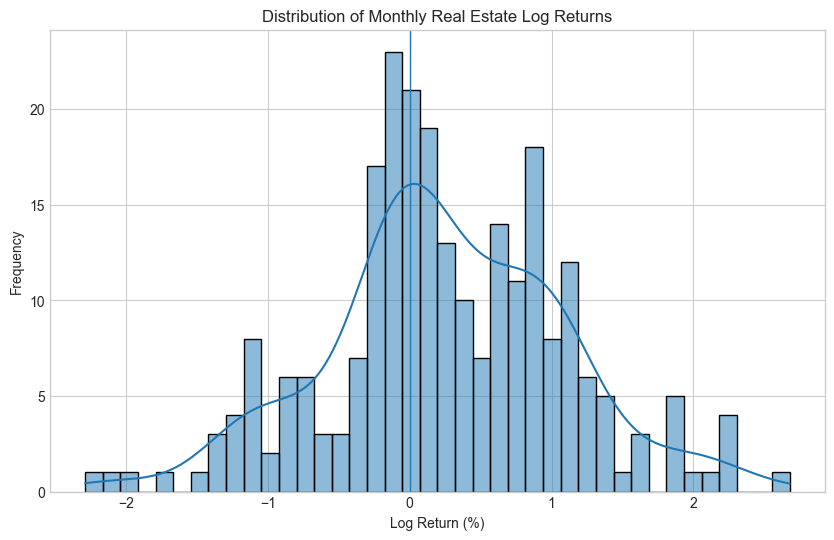

In [28]:
plt.figure(figsize=(10, 6))

sns.histplot(
    monthly["Case_Shiller_Log_Return_Pct"].dropna(),
    bins=40,
    kde=True
)

plt.axvline(0, linewidth=1)

plt.title("Distribution of Monthly Real Estate Log Returns")
plt.xlabel("Log Return (%)")
plt.ylabel("Frequency")

plt.show()

In [29]:
returns = monthly["Case_Shiller_Log_Return"].dropna()

statistics = pd.Series({
    "Mean Monthly Return": returns.mean(),
    "Monthly Volatility": returns.std(),
    "Annualized Return": returns.mean() * 12,
    "Annualized Volatility": returns.std() * np.sqrt(12),
    "Minimum Monthly Return": returns.min(),
    "Maximum Monthly Return": returns.max(),
    "Skewness": returns.skew(),
    "Kurtosis": returns.kurtosis()
})

statistics

Mean Monthly Return       0.002516
Monthly Volatility        0.008380
Annualized Return         0.030196
Annualized Volatility     0.029030
Minimum Monthly Return   -0.022865
Maximum Monthly Return    0.026782
Skewness                 -0.044256
Kurtosis                  0.358723
dtype: float64

In [30]:
Q1 = returns.quantile(0.25)
Q3 = returns.quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = returns[
    (returns < lower) |
    (returns > upper)
]

outliers

DATE
2008-11-30   -0.019605
2008-12-31   -0.022865
2009-01-31   -0.021087
2022-03-31    0.026782
Name: Case_Shiller_Log_Return, dtype: float64

In [34]:
monthly["Case_Shiller_Log_Return"] = (
    np.log(monthly["Case_Shiller_HPI"]).diff()
)

monthly["FHFA_Log_Return"] = (
    np.log(monthly["FHFA_HPI"]).diff()
)

case_shiller_returns = monthly["Case_Shiller_Log_Return"].dropna()
fhfa_returns = monthly["FHFA_Log_Return"].dropna()

In [35]:
def adf_test(series, name):
    
    result = adfuller(
        series,
        autolag="AIC"
    )
    
    print("=" * 60)
    print(f"ADF Test: {name}")
    print("=" * 60)
    
    print(f"ADF Statistic: {result[0]:.6f}")
    print(f"p-value:       {result[1]:.6f}")
    print(f"Lags Used:     {result[2]}")
    print(f"Observations:   {result[3]}")
    
    print("\nCritical Values:")
    
    for key, value in result[4].items():
        print(f"  {key}: {value:.6f}")
    
    if result[1] < 0.05:
        print("\nConclusion: Reject H0 → Series appears stationary.")
    else:
        print("\nConclusion: Fail to reject H0 → Series may be non-stationary.")

In [36]:
adf_test(
    monthly["Case_Shiller_HPI"].dropna(),
    "Case-Shiller HPI"
)

adf_test(
    case_shiller_returns,
    "Case-Shiller Log Returns"
)
adf_test(
    monthly["FHFA_HPI"].dropna(),
    "FHFA HPI"
)

adf_test(
    fhfa_returns,
    "FHFA Log Returns"
)

ADF Test: Case-Shiller HPI
ADF Statistic: 0.213105
p-value:       0.972987
Lags Used:     14
Observations:   233

Critical Values:
  1%: -3.458731
  5%: -2.874026
  10%: -2.573424

Conclusion: Fail to reject H0 → Series may be non-stationary.
ADF Test: Case-Shiller Log Returns
ADF Statistic: -2.416333
p-value:       0.137180
Lags Used:     13
Observations:   233

Critical Values:
  1%: -3.458731
  5%: -2.874026
  10%: -2.573424

Conclusion: Fail to reject H0 → Series may be non-stationary.
ADF Test: FHFA HPI
ADF Statistic: -0.401483
p-value:       0.909851
Lags Used:     7
Observations:   240

Critical Values:
  1%: -3.457894
  5%: -2.873659
  10%: -2.573229

Conclusion: Fail to reject H0 → Series may be non-stationary.
ADF Test: FHFA Log Returns
ADF Statistic: -1.675268
p-value:       0.443898
Lags Used:     6
Observations:   240

Critical Values:
  1%: -3.457894
  5%: -2.873659
  10%: -2.573229

Conclusion: Fail to reject H0 → Series may be non-stationary.


In [37]:
def get_adf_results(series, name):
    
    result = adfuller(series.dropna(), autolag="AIC")
    
    return {
        "Series": name,
        "ADF Statistic": result[0],
        "p-value": result[1],
        "1% Critical Value": result[4]["1%"],
        "5% Critical Value": result[4]["5%"],
        "10% Critical Value": result[4]["10%"],
        "Stationary": "Yes" if result[1] < 0.05 else "No"
    }


adf_results = pd.DataFrame([
    get_adf_results(
        monthly["Case_Shiller_HPI"],
        "Case-Shiller HPI"
    ),
    
    get_adf_results(
        monthly["Case_Shiller_Log_Return"],
        "Case-Shiller Log Return"
    ),
    
    get_adf_results(
        monthly["FHFA_HPI"],
        "FHFA HPI"
    ),
    
    get_adf_results(
        monthly["FHFA_Log_Return"],
        "FHFA Log Return"
    )
])

adf_results

,Series,ADF Statistic,p-value,1% Critical Value,5% Critical Value,10% Critical Value,Stationary
0,Case-Shiller HPI,0.213105,0.972987,-3.458731,-2.874026,-2.573424,No
1,Case-Shiller Log Return,-2.416333,0.137180,-3.458731,-2.874026,-2.573424,No
2,FHFA HPI,-0.401483,0.909851,-3.457894,-2.873659,-2.573229,No
3,FHFA Log Return,-1.675268,0.443898,-3.457894,-2.873659,-2.573229,No


In [38]:
from statsmodels.tsa.stattools import kpss

In [39]:
def kpss_test(series, name):
    
    result = kpss(
        series.dropna(),
        regression="c",
        nlags="auto"
    )
    
    print("=" * 60)
    print(f"KPSS Test: {name}")
    print("=" * 60)
    
    print(f"KPSS Statistic: {result[0]:.6f}")
    print(f"p-value:        {result[1]:.6f}")
    print(f"Lags Used:      {result[2]}")
    
    print("\nCritical Values:")
    
    for key, value in result[3].items():
        print(f"  {key}: {value:.6f}")
    
    if result[1] < 0.05:
        print("\nConclusion: Reject H0 → Evidence of non-stationarity.")
    else:
        print("\nConclusion: Fail to reject H0 → Series appears stationary.")

In [40]:
kpss_test(
    monthly["Case_Shiller_HPI"],
    "Case-Shiller HPI"
)

kpss_test(
    monthly["Case_Shiller_Log_Return"],
    "Case-Shiller Log Returns"
)

KPSS Test: Case-Shiller HPI
KPSS Statistic: 1.934891
p-value:        0.010000
Lags Used:      10

Critical Values:
  10%: 0.347000
  5%: 0.463000
  2.5%: 0.574000
  1%: 0.739000

Conclusion: Reject H0 → Evidence of non-stationarity.
KPSS Test: Case-Shiller Log Returns
KPSS Statistic: 0.918026
p-value:        0.010000
Lags Used:      8

Critical Values:
  10%: 0.347000
  5%: 0.463000
  2.5%: 0.574000
  1%: 0.739000

Conclusion: Reject H0 → Evidence of non-stationarity.
